In [104]:
import pandas as pd 
import numpy as np
import sklearn as sk 
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import RandomForestClassifier 
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix 
from sklearn.preprocessing import LabelEncoder 

In [105]:
df=pd.read_csv("digitalTwin.csv")

In [106]:
df 


,Equipment,HealthIndex,EngineTemp,Vibration,Pressure,State
0,EQ-240,90.74,67.81,3.91,292.70,Warning
1,EQ-14,84.60,53.83,2.46,284.46,Warning
2,EQ-270,88.32,66.18,8.93,128.07,Critical
3,EQ-106,27.12,99.42,4.99,102.04,Healthy
4,EQ-175,92.48,112.92,4.23,282.61,Critical
...,...,...,...,...,...,...
9995,EQ-5,27.09,54.86,6.64,202.40,Critical
9996,EQ-48,49.08,71.36,3.42,170.46,Healthy
9997,EQ-44,66.03,64.35,3.60,126.46,Critical
9998,EQ-17,50.77,98.30,9.97,312.12,Healthy


In [107]:
df.isnull().sum()

Equipment      0
HealthIndex    0
EngineTemp     0
Vibration      0
Pressure       0
State          0
dtype: int64

In [108]:
df.dtypes 

Equipment       object
HealthIndex    float64
EngineTemp     float64
Vibration      float64
Pressure       float64
State           object
dtype: object

In [109]:
X = df.drop(["State", "Equipment"], axis=1)
y=df["State"]

In [110]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [111]:
X_train.shape 

(8000, 4)

In [112]:
X_train.dtypes 

HealthIndex    float64
EngineTemp     float64
Vibration      float64
Pressure       float64
dtype: object

In [113]:
df.info

<bound method DataFrame.info of      Equipment  HealthIndex  EngineTemp  Vibration  Pressure     State
0       EQ-240        90.74       67.81       3.91    292.70   Warning
1        EQ-14        84.60       53.83       2.46    284.46   Warning
2       EQ-270        88.32       66.18       8.93    128.07  Critical
3       EQ-106        27.12       99.42       4.99    102.04   Healthy
4       EQ-175        92.48      112.92       4.23    282.61  Critical
...        ...          ...         ...        ...       ...       ...
9995      EQ-5        27.09       54.86       6.64    202.40  Critical
9996     EQ-48        49.08       71.36       3.42    170.46   Healthy
9997     EQ-44        66.03       64.35       3.60    126.46  Critical
9998     EQ-17        50.77       98.30       9.97    312.12   Healthy
9999    EQ-170        87.37      105.95       7.27    308.28   Healthy

[10000 rows x 6 columns]>

In [114]:
le=LabelEncoder()



In [115]:
model=RandomForestClassifier(random_state=42)

In [116]:
df 


,Equipment,HealthIndex,EngineTemp,Vibration,Pressure,State
0,EQ-240,90.74,67.81,3.91,292.70,Warning
1,EQ-14,84.60,53.83,2.46,284.46,Warning
2,EQ-270,88.32,66.18,8.93,128.07,Critical
3,EQ-106,27.12,99.42,4.99,102.04,Healthy
4,EQ-175,92.48,112.92,4.23,282.61,Critical
...,...,...,...,...,...,...
9995,EQ-5,27.09,54.86,6.64,202.40,Critical
9996,EQ-48,49.08,71.36,3.42,170.46,Healthy
9997,EQ-44,66.03,64.35,3.60,126.46,Critical
9998,EQ-17,50.77,98.30,9.97,312.12,Healthy


In [117]:
print(df["State"].unique())

['Warning' 'Critical' 'Healthy']


In [118]:
model.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [119]:
y_pred=model.predict(X_test)

In [120]:
accuracy=accuracy_score(y_pred,y_test)

In [121]:
conf_matrix=confusion_matrix(y_pred,y_test)

In [122]:
classif=classification_report(y_pred,y_pred)

In [123]:
print(f"precision:{accuracy:0.4f}")

precision:0.3415


In [125]:
print("\nmatrice de confusion:",conf_matrix)


matrice de confusion: [[213 230 239]
 [221 247 205]
 [225 197 223]]


In [126]:
print("\nrapport de classification:",classif)


rapport de classification:               precision    recall  f1-score   support

    Critical       1.00      1.00      1.00       682
     Healthy       1.00      1.00      1.00       673
     Warning       1.00      1.00      1.00       645

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [128]:
from sklearn.metrics import  ConfusionMatrixDisplay


matrice de confusion: [[213 230 239]
 [221 247 205]
 [225 197 223]]


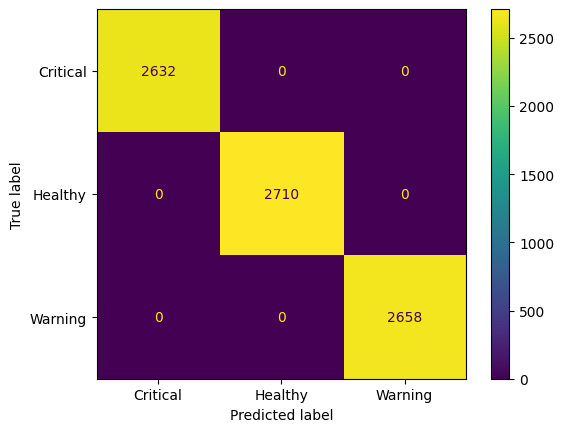

In [132]:
print("\nmatrice de confusion:",conf_matrix);
_=ConfusionMatrixDisplay.from_estimator(model,X_train,y_train)

In [133]:
print(df["State"].value_counts())


State
Healthy     3384
Warning     3325
Critical    3291
Name: count, dtype: int64
